# COMP4318/5318 Assignment 2: Image Classification

### Group number: ...  , SID1: ... , SID2: ..., SID3: ..., SID4: ... 

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment. 

In [1]:
# File paths and runtime measurement
from pathlib import Path
from time import perf_counter

# Data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Neural network
import keras
from keras import layers

# Preprocessing, hyperparameter search, and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Random seed for reproducibility
SEED_MLP = 42
keras.utils.set_random_seed(SEED_MLP)

## 1. Data loading, exploration, and preprocessing


Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [2]:
DATA_DIR = Path.cwd()

# Load the shared features and integer class labels.
X_train_all_mlp = np.load(
    DATA_DIR / "X_train_features.npy", allow_pickle=False
)
y_train_all_mlp = np.load(
    DATA_DIR / "y_train.npy", allow_pickle=False
).astype("int64")

# Reuse Member A's training/validation split.
with np.load(DATA_DIR / "split_indices.npz",
             allow_pickle=False) as split:
    fit_idx_mlp = split["fit_idx"]
    val_idx_mlp = split["val_idx"]

X_fit_mlp = X_train_all_mlp[fit_idx_mlp]
y_fit_mlp = y_train_all_mlp[fit_idx_mlp]

X_val_mlp = X_train_all_mlp[val_idx_mlp]
y_val_mlp = y_train_all_mlp[val_idx_mlp]

print("Training subset:", X_fit_mlp.shape)
print("Validation subset:", X_val_mlp.shape)
print("Number of classes:", len(np.unique(y_train_all_mlp)))

Training subset: (25600, 357)
Validation subset: (6400, 357)
Number of classes: 9


In [3]:
# Fit the scaler on the training subset only.
scaler_mlp = StandardScaler()

X_fit_scaled_mlp = scaler_mlp.fit_transform(
    X_fit_mlp
).astype("float32")

# Transform validation data using the same scaler.
X_val_scaled_mlp = scaler_mlp.transform(
    X_val_mlp
).astype("float32")

### Examples of preprocessed data
Please print/display some examples of your preprocessed data here.

In [4]:
# Display selected features from five preprocessed samples.
preview_mlp = pd.DataFrame(
    X_fit_scaled_mlp[:5, :8],
    columns=[f"feature_{i}" for i in range(8)],
)
preview_mlp["label"] = y_fit_mlp[:5]

preview_mlp.round(4)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,label
0,-0.2954,-1.0280,-0.8378,0.4223,0.1470,0.2815,-0.1469,-0.9269,2
1,-0.5307,-0.2260,-0.4236,-0.4095,-0.1423,-0.3145,-0.5028,-0.1509,3
2,0.6795,0.3946,0.6006,0.5434,-0.1626,0.2020,0.3680,-0.2999,5
3,1.4819,1.9910,1.7417,1.6668,2.2299,1.9767,1.6821,2.2516,0
4,-1.8866,-1.5819,-1.8268,-2.1922,-1.6855,-1.9634,0.6008,1.1637,8


## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

### Fully connected neural network

The MLP uses the 357 image features extracted by Member A. We reuse the shared training/validation indices to ensure consistent model comparison. Features are standardised using statistics fitted only on the training subset during tuning.

The network contains two fully connected hidden layers with ReLU activations, with Dropout after each hidden layer. We compare two network sizes to investigate model capacity. Dropout is included as a regularisation option to reduce overfitting. The output layer uses nine softmax units for the nine classes. We use the Adam optimiser and sparse categorical cross-entropy because the labels are integer class IDs.

This approach can learn nonlinear relationships between the extracted features. However, its performance depends on the information retained by feature extraction, and it does not directly learn spatial image patterns as a CNN does.

In [5]:
def build_mlp(
    input_dim,
    num_classes,
    hidden_units=(128, 64),
    dropout_rate=0.2,
    learning_rate=0.001,
):
    """Build and compile a configurable MLP classifier."""
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(input_dim,)))

    # Fully connected hidden layers
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(dropout_rate))

    # Output probabilities for all classes
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


# Create an initial model and display its architecture.
keras.utils.set_random_seed(SEED_MLP)

initial_mlp = build_mlp(
    input_dim=X_fit_scaled_mlp.shape[1],
    num_classes=len(np.unique(y_train_all_mlp)),
)

initial_mlp.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        45,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,665 (213.54 KB)

 Trainable params: 54,665 (213.54 KB)

 Non-trainable params: 0 (0.00 B)

### Convolutional neural network

## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

### Fully connected neural network

In [6]:
# Compare three hyperparameters across eight configurations.
param_grid_mlp = {
    "hidden_units": [(128, 64), (256, 128)],
    "dropout_rate": [0.0, 0.2],
    "learning_rate": [0.001, 0.0003],
}

MAX_EPOCHS_MLP = 60
BATCH_SIZE_MLP = 128
PATIENCE_MLP = 8

configs_mlp = list(ParameterGrid(param_grid_mlp))
print("Number of configurations:", len(configs_mlp))

Number of configurations: 8


We evaluate eight configurations by varying three hyperparameters: hidden-layer sizes [(128, 64), (256, 128)], Dropout rate [0.0, 0.2], and learning rate [0.001, 0.0003]. These choices compare network capacity, regularisation, and optimisation step size while keeping the search computationally manageable.

All configurations use the same training/validation split, random seed, batch size of 128, and maximum of 60 epochs. Early stopping monitors validation loss with a patience of eight epochs and restores the weights with the lowest validation loss. Configurations are ranked by validation macro F1, with accuracy as the secondary criterion. Macro F1 gives equal importance to each class despite differences in class frequency.

In [7]:
results_mlp = []
histories_mlp = {}

for trial_id, config in enumerate(configs_mlp, start=1):
    # Start each configuration with a fresh model.
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_MLP)

    print(f"\nConfiguration {trial_id}/{len(configs_mlp)}: {config}")

    start_time = perf_counter()

    model_mlp = build_mlp(
        input_dim=X_fit_scaled_mlp.shape[1],
        num_classes=len(np.unique(y_train_all_mlp)),
        **config,
    )

    early_stopping_mlp = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PATIENCE_MLP,
        restore_best_weights=True,
    )

    history_mlp = model_mlp.fit(
        X_fit_scaled_mlp,
        y_fit_mlp,
        validation_data=(X_val_scaled_mlp, y_val_mlp),
        epochs=MAX_EPOCHS_MLP,
        batch_size=BATCH_SIZE_MLP,
        callbacks=[early_stopping_mlp],
        shuffle=True,
        verbose=0,
    )

    fit_seconds = perf_counter() - start_time

    # Evaluate the restored model on the validation set.
    val_probabilities = model_mlp.predict(
        X_val_scaled_mlp, verbose=0
    )
    val_predictions = np.argmax(val_probabilities, axis=1)

    val_accuracy = accuracy_score(y_val_mlp, val_predictions)
    val_macro_f1 = f1_score(
        y_val_mlp,
        val_predictions,
        average="macro",
        zero_division=0,
    )

    best_epoch = int(
        np.argmin(history_mlp.history["val_loss"]) + 1
    )

    results_mlp.append({
        "trial": trial_id,
        **config,
        "best_epoch": best_epoch,
        "epochs_run": len(history_mlp.history["loss"]),
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "fit_seconds": fit_seconds,
    })

    # Keep learning curves for later plots.
    histories_mlp[trial_id] = history_mlp.history

    print(
        f"Validation accuracy: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f} | "
        f"Time: {fit_seconds:.1f}s"
    )

# Rank configurations by macro F1, then accuracy.
results_df_mlp = pd.DataFrame(results_mlp).sort_values(
    by=["val_macro_f1", "val_accuracy"],
    ascending=[False, False],
).reset_index(drop=True)

results_df_mlp.round(4)


Configuration 1/8: {'dropout_rate': 0.0, 'hidden_units': (128, 64), 'learning_rate': 0.001}
Validation accuracy: 0.8344 | Macro F1: 0.8311 | Time: 2.4s

Configuration 2/8: {'dropout_rate': 0.0, 'hidden_units': (128, 64), 'learning_rate': 0.0003}
Validation accuracy: 0.8419 | Macro F1: 0.8380 | Time: 4.4s

Configuration 3/8: {'dropout_rate': 0.0, 'hidden_units': (256, 128), 'learning_rate': 0.001}
Validation accuracy: 0.8348 | Macro F1: 0.8322 | Time: 2.9s

Configuration 4/8: {'dropout_rate': 0.0, 'hidden_units': (256, 128), 'learning_rate': 0.0003}
Validation accuracy: 0.8455 | Macro F1: 0.8407 | Time: 3.9s

Configuration 5/8: {'dropout_rate': 0.2, 'hidden_units': (128, 64), 'learning_rate': 0.001}
Validation accuracy: 0.8598 | Macro F1: 0.8547 | Time: 4.5s

Configuration 6/8: {'dropout_rate': 0.2, 'hidden_units': (128, 64), 'learning_rate': 0.0003}
Validation accuracy: 0.8620 | Macro F1: 0.8570 | Time: 8.5s

Configuration 7/8: {'dropout_rate': 0.2, 'hidden_units': (256, 128), 'learni

,trial,dropout_rate,hidden_units,learning_rate,best_epoch,epochs_run,val_accuracy,val_macro_f1,fit_seconds
0,8,0.2,"(256, 128)",0.0003,33,41,0.8661,0.8606,7.6142
1,7,0.2,"(256, 128)",0.0010,13,21,0.8622,0.8577,4.0676
2,6,0.2,"(128, 64)",0.0003,50,58,0.8620,0.8570,8.4713
3,5,0.2,"(128, 64)",0.0010,21,29,0.8598,0.8547,4.4635
4,4,0.0,"(256, 128)",0.0003,13,21,0.8455,0.8407,3.8552
5,2,0.0,"(128, 64)",0.0003,21,29,0.8419,0.8380,4.3670
6,3,0.0,"(256, 128)",0.0010,8,16,0.8348,0.8322,2.9271
7,1,0.0,"(128, 64)",0.0010,7,15,0.8344,0.8311,2.3994


The selected configuration uses hidden layers of (256, 128), a Dropout rate of 0.2, and a learning rate of 0.0003. It achieves validation macro F1 of 0.8606 and accuracy of 0.8661. Although another configuration achieves slightly higher accuracy (0.8622), its macro F1 is lower (0.8577), so it is not selected.

Dropout improves validation macro F1 in all four matched comparisons in this search. The lower learning rate also performs better in each matched comparison, although it generally requires more training epochs. These findings are limited to the tested configurations and the single split and seed used.

The learning curves show a widening gap between training and validation performance. Training loss continues to decrease while validation loss largely plateaus, indicating overfitting. The lowest validation loss occurs at epoch 33, which determines the training duration for the final model.

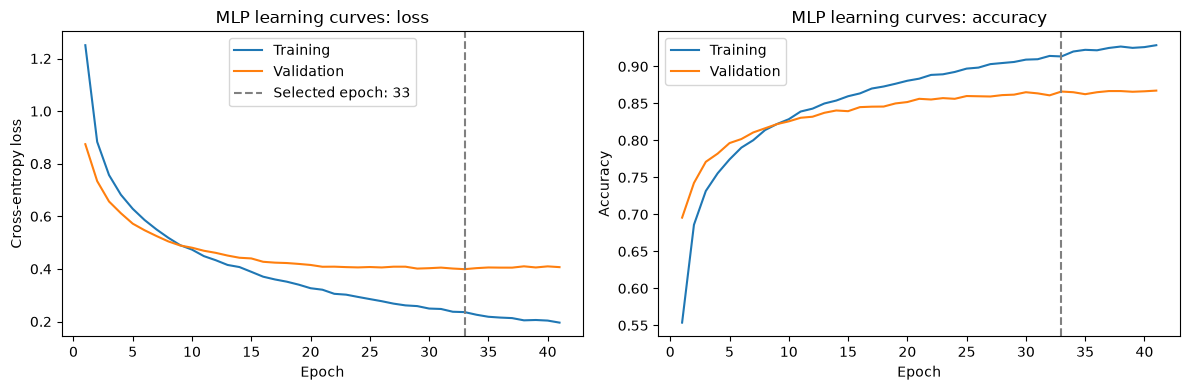

In [8]:
# Retrieve the learning history of the selected configuration.
best_trial_mlp = int(results_df_mlp.iloc[0]["trial"])
best_history_mlp = histories_mlp[best_trial_mlp]
best_epoch_mlp = int(results_df_mlp.iloc[0]["best_epoch"])

epochs_mlp = range(1, len(best_history_mlp["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training and validation loss
axes[0].plot(
    epochs_mlp, best_history_mlp["loss"], label="Training"
)
axes[0].plot(
    epochs_mlp, best_history_mlp["val_loss"], label="Validation"
)
axes[0].axvline(
    best_epoch_mlp, color="grey", linestyle="--",
    label=f"Selected epoch: {best_epoch_mlp}",
)
axes[0].set_title("MLP learning curves: loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

# Training and validation accuracy
axes[1].plot(
    epochs_mlp, best_history_mlp["accuracy"], label="Training"
)
axes[1].plot(
    epochs_mlp, best_history_mlp["val_accuracy"], label="Validation"
)
axes[1].axvline(
    best_epoch_mlp, color="grey", linestyle="--"
)
axes[1].set_title("MLP learning curves: accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### Convolutional neural network

## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

### Fully connected neural network

In [9]:
# Configuration selected using validation macro F1.
FINAL_CONFIG_MLP = {
    "hidden_units": (256, 128),
    "dropout_rate": 0.2,
    "learning_rate": 0.0003,
}
FINAL_EPOCHS_MLP = 33
FINAL_BATCH_SIZE_MLP = 128

keras.backend.clear_session()
keras.utils.set_random_seed(SEED_MLP)

start_time_mlp = perf_counter()

# Refit preprocessing on the complete training set.
final_scaler_mlp = StandardScaler()
X_train_final_mlp = final_scaler_mlp.fit_transform(
    X_train_all_mlp
).astype("float32")

# Train a fresh model using all training samples.
final_model_mlp = build_mlp(
    input_dim=X_train_final_mlp.shape[1],
    num_classes=len(np.unique(y_train_all_mlp)),
    **FINAL_CONFIG_MLP,
)

final_history_mlp = final_model_mlp.fit(
    X_train_final_mlp,
    y_train_all_mlp,
    epochs=FINAL_EPOCHS_MLP,
    batch_size=FINAL_BATCH_SIZE_MLP,
    shuffle=True,
    verbose=0,
)

final_fit_seconds_mlp = perf_counter() - start_time_mlp

print("Final configuration:", FINAL_CONFIG_MLP)
print("Training samples:", len(y_train_all_mlp))
print("Training epochs:", FINAL_EPOCHS_MLP)
print(
    f"Preprocessing and training time: "
    f"{final_fit_seconds_mlp:.2f}s"
)

Final configuration: {'hidden_units': (256, 128), 'dropout_rate': 0.2, 'learning_rate': 0.0003}
Training samples: 32000
Training epochs: 33
Preprocessing and training time: 6.44s


In [10]:
# Load the held-out test set for final evaluation.
X_test_mlp = np.load(
    DATA_DIR / "X_test_features.npy", allow_pickle=False
)
y_test_mlp = np.load(
    DATA_DIR / "y_test.npy", allow_pickle=False
).astype("int64").ravel()

start_time_mlp = perf_counter()

# Apply preprocessing learned from the complete training set.
X_test_scaled_mlp = final_scaler_mlp.transform(
    X_test_mlp
).astype("float32")

test_probabilities_mlp = final_model_mlp.predict(
    X_test_scaled_mlp, verbose=0
)
test_predictions_mlp = np.argmax(
    test_probabilities_mlp, axis=1
)

test_predict_seconds_mlp = perf_counter() - start_time_mlp

test_accuracy_mlp = accuracy_score(
    y_test_mlp, test_predictions_mlp
)
test_macro_f1_mlp = f1_score(
    y_test_mlp, test_predictions_mlp,
    average="macro", zero_division=0,
)
test_weighted_f1_mlp = f1_score(
    y_test_mlp, test_predictions_mlp,
    average="weighted", zero_division=0,
)

print(f"Test accuracy: {test_accuracy_mlp:.4f}")
print(f"Test macro F1: {test_macro_f1_mlp:.4f}")
print(f"Test weighted F1: {test_weighted_f1_mlp:.4f}")
print(
    f"Test preprocessing and prediction time: "
    f"{test_predict_seconds_mlp:.2f}s"
)

print("\nClassification report:")
print(classification_report(
    y_test_mlp,
    test_predictions_mlp,
    digits=4,
    zero_division=0,
))

Test accuracy: 0.8772
Test macro F1: 0.8737
Test weighted F1: 0.8770
Test preprocessing and prediction time: 0.09s

Classification report:
              precision    recall  f1-score   support

           0     0.9577    0.9863    0.9718       873
           1     0.9860    0.9872    0.9866       858
           2     0.8486    0.7412    0.7912       877
           3     0.9626    0.9573    0.9600       914
           4     0.8552    0.8738    0.8644       737
           5     0.8810    0.8498    0.8651      1072
           6     0.7762    0.8035    0.7896       682
           7     0.7337    0.7761    0.7543       813
           8     0.8657    0.8952    0.8802      1174

    accuracy                         0.8772      8000
   macro avg     0.8741    0.8745    0.8737      8000
weighted avg     0.8779    0.8772    0.8770      8000



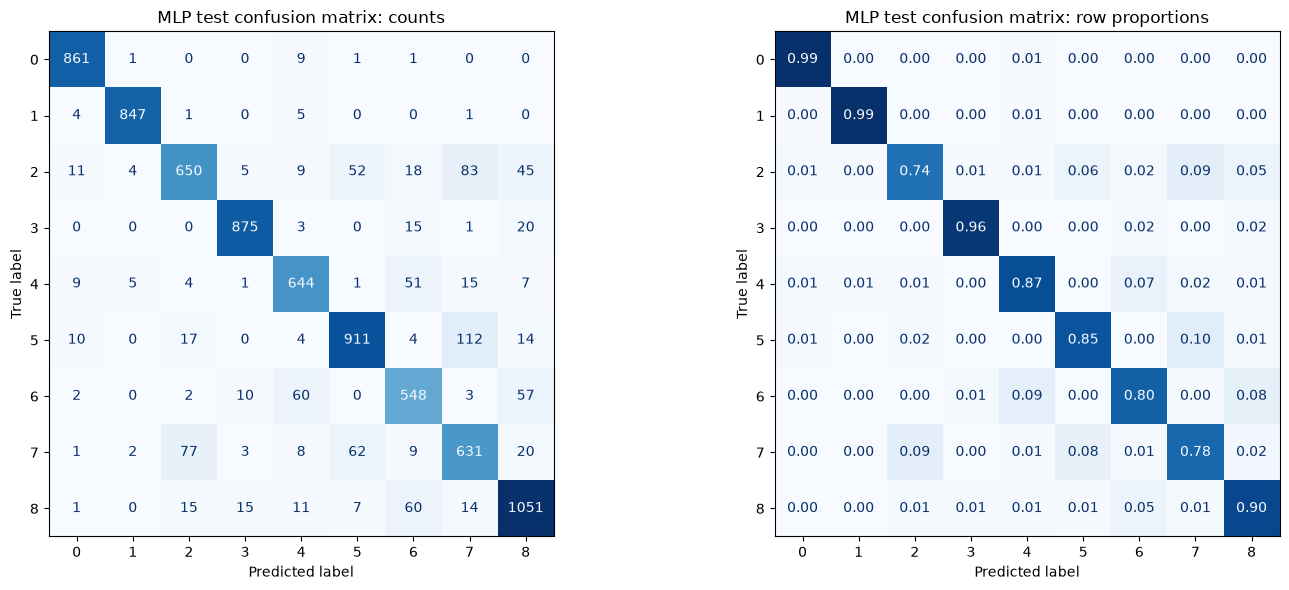

In [11]:
# Display counts and recall-normalised confusion matrices.
class_labels_mlp = np.unique(y_train_all_mlp)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_mlp,
    test_predictions_mlp,
    labels=class_labels_mlp,
    display_labels=class_labels_mlp,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("MLP test confusion matrix: counts")

ConfusionMatrixDisplay.from_predictions(
    y_test_mlp,
    test_predictions_mlp,
    labels=class_labels_mlp,
    display_labels=class_labels_mlp,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("MLP test confusion matrix: row proportions")

plt.tight_layout()
plt.show()

The final MLP is retrained from scratch on all 32,000 training samples for 33 epochs using the selected configuration. Standardisation is refitted on the complete training set and then applied to the test set. The final training and evaluation cells use explicitly specified settings and do not depend on executing the tuning cells.

On the 8,000 test samples, the model achieves accuracy of 0.8772, macro F1 of 0.8737, and weighted F1 of 0.8770. Standardisation and model training take 6.44 seconds, while test standardisation and prediction take 0.09 seconds on the local machine.

Performance varies across classes. Classes 0, 1, and 3 have F1 scores above 0.96, whereas class 7 has the lowest F1 score (0.7543). The confusion matrix shows that 112 class-5 samples are predicted as class 7, while classes 2 and 7 are confused in both directions (83 and 77 samples, respectively). These errors indicate that the model does not separate all classes equally well using the extracted features. Test results are reported for final evaluation and are not used to revise the selected configuration.

### Convolutional neural network

## 5. AI Acknowledgement
ChatGPT was used to assist with Python environment troubleshooting, code review and refinement, and interpretation of experimental outputs. The experiments were executed locally, and the reported numerical results were obtained from those runs.